# Supplementary Figure 15

Measured computational resources of the CPU production workflow. Four heatmaps share one
layout of seven workflow stages (rows) by four cohorts (columns): a, median task execution
minutes; b, median usable sampled memory (GiB); c, sum of allocated CPU-hours; d, usable memory
samples per number of tasks. Shading is log10(1 + value); printed values are untransformed.

The notebook draws the producer figure (the v28f image) and the v30 house-style redraw of the
same values (`SFig15_v30`), which is the figure placed from v30 on.

Run from the repository root: `python paper.py build SFig15`.

In [1]:
from pathlib import Path
import sys
UNIT = Path.cwd()                 # the notebook runs with its own directory as cwd
REPO = UNIT.parents[1]
sys.path[:0] = [str(REPO), str(UNIT)]
SD = REPO / "source_data" / UNIT.name
OUT = REPO / "build" / UNIT.name   # rendered panels; gitignored
OUT.mkdir(parents=True, exist_ok=True)
from style import fl_style as fl
import panels
fl.init()

## Panels a-d: stage summary and drawing

The original producer draws the four panels together in one matplotlib figure, so they are
drawn together here (`panels.draw_figure`), then the in-image title is removed and the page is
rendered at 300 dpi (`panels.redact_title`), as in the producer's second step. The producer set
its own typeface (DejaVu Sans, shipped with matplotlib), so the drawing does not depend on the
Söhne fonts.

The stage summary the figure draws is first recomputed from the per-task Slurm records
(`panels.stage_summary`, the producer's own summary loop) and must equal the shipped table byte
for byte.

n: per-acquisition stages use 15 CAMPI, 58 healthy-stool, 306 PREDICT and 347 CapScan acquisitions
(one Slurm task per acquisition); shared stages are one task per cohort, run over 97 healthy-stool,
306 PREDICT and 368 CapScan acquisitions. Test: none (descriptive).

stage summary recomputed from 2905 task records: byte-identical to compute_stage_summary.tsv


x tick labels: ['CAMPI 15', 'Stool 58', 'PREDICT 306', 'CapScan 347']


{'title_bbox': [93.67, 8.076, 417.51, 20.891], 'rect': [0.0, 0.0, 511.20001220703125, 496.79998779296875]}


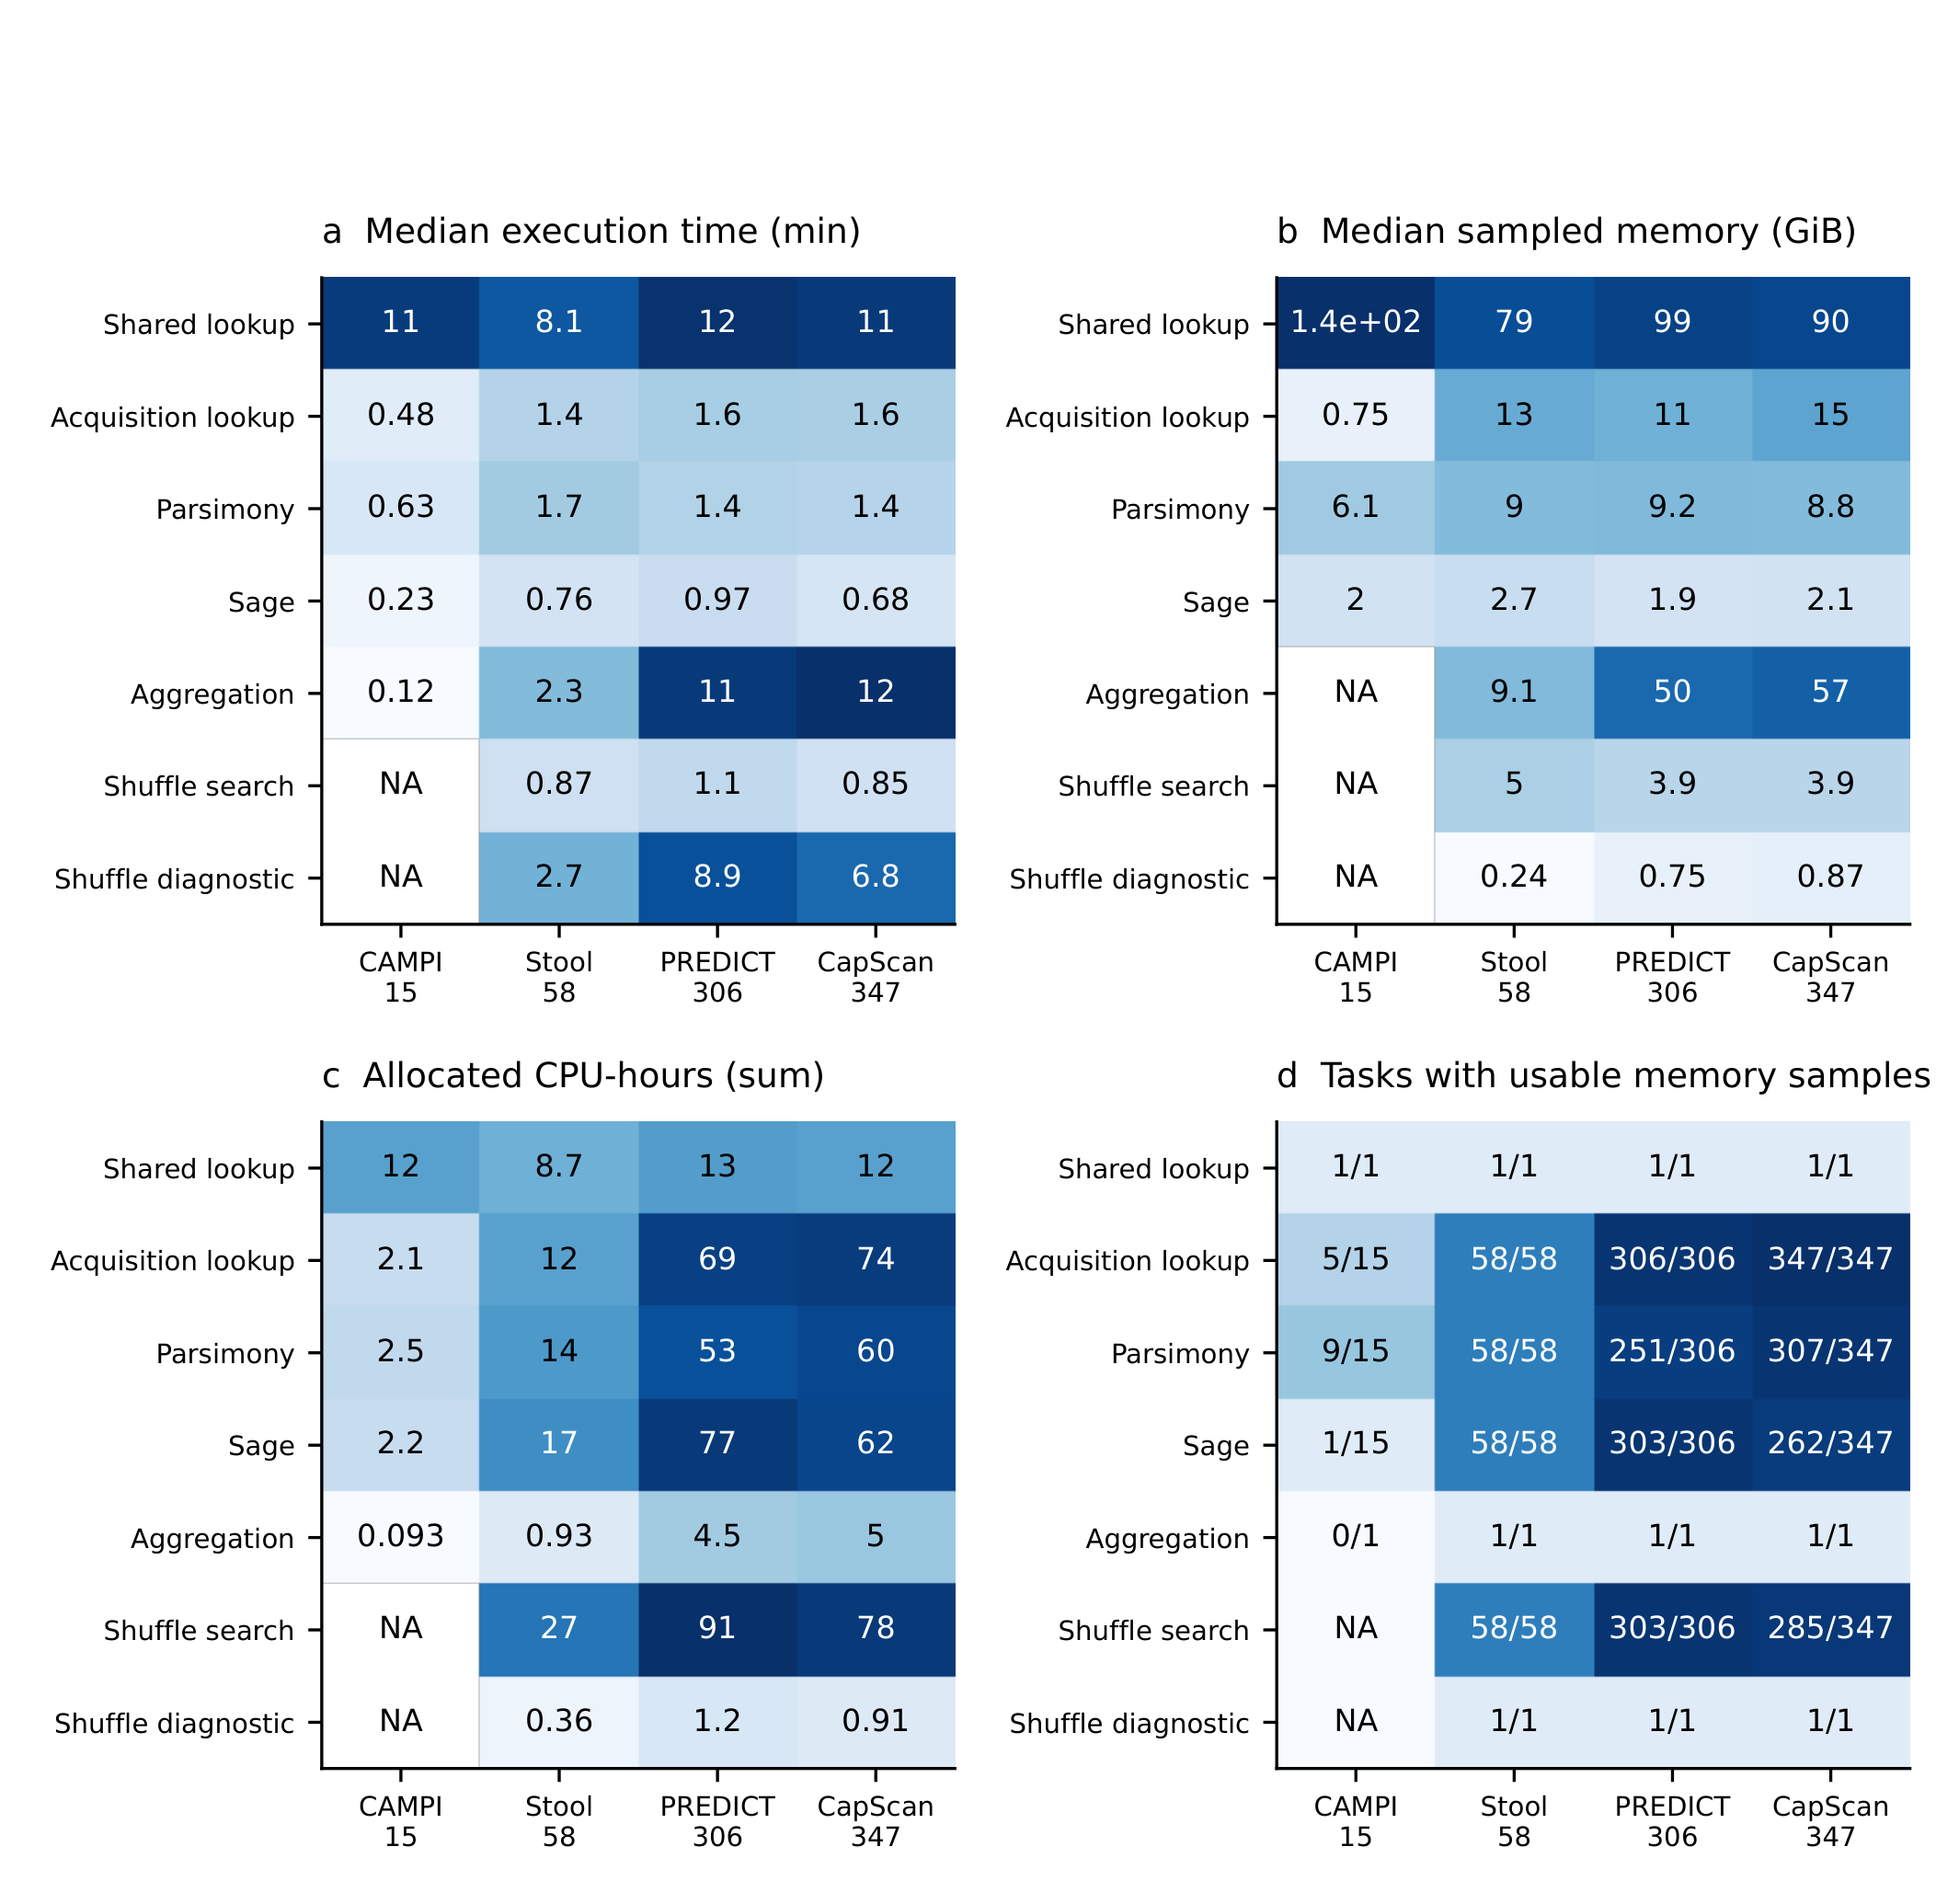

In [2]:
from IPython.display import Image, display
panels.check_sha256(SD / "compute_stage_summary.tsv", panels.SUMMARY_SHA256)
panels.check_sha256(SD / "compute_task_records.tsv", panels.RECORDS_SHA256)
s = panels.load_summary(SD / "compute_stage_summary.tsv")
jobs = panels.load_records(SD / "compute_task_records.tsv")
recomputed = panels.stage_summary(jobs).to_csv(sep="\t", index=False)
assert recomputed == (SD / "compute_stage_summary.tsv").read_text(), "stage summary differs from task records"
print("stage summary recomputed from", len(jobs), "task records: byte-identical to compute_stage_summary.tsv")
xt = panels.draw_figure(s, OUT / "panels_abcd.pdf")
print("x tick labels:", [x.replace(chr(10), " ") for x in xt])
print(panels.redact_title(OUT / "panels_abcd.pdf", OUT / "SFig15_v28f.pdf", OUT / "SFig15_v28f.png"))
display(Image(filename=str(OUT / "SFig15_v28f.png"), width=720))

## v30 composite (house style)

The figure as placed in the manuscript from v30 on: the same data and plotted values, redrawn in
the house style (`panels.figure_v30`, port of the v30 restyle script). The function first runs the
producer drawing above with saving intercepted, then compares every plotted array of the restyled
figure with it exactly and raises on any difference. Output: `SFig15_v30.pdf` and the PDF
rasterised at 300 dpi, `SFig15_v30.png`. The house style needs the Söhne fonts
(`FASTALAKE_FONT_DIR`) for its text pixels.


axes 0: images 1, point sets 0, segment sets 0, lines 0, data texts 28, values compared 28: IDENTICAL
axes 1: images 1, point sets 0, segment sets 0, lines 0, data texts 28, values compared 28: IDENTICAL
axes 2: images 1, point sets 0, segment sets 0, lines 0, data texts 28, values compared 28: IDENTICAL
axes 3: images 1, point sets 0, segment sets 0, lines 0, data texts 28, values compared 28: IDENTICAL
clip check: True


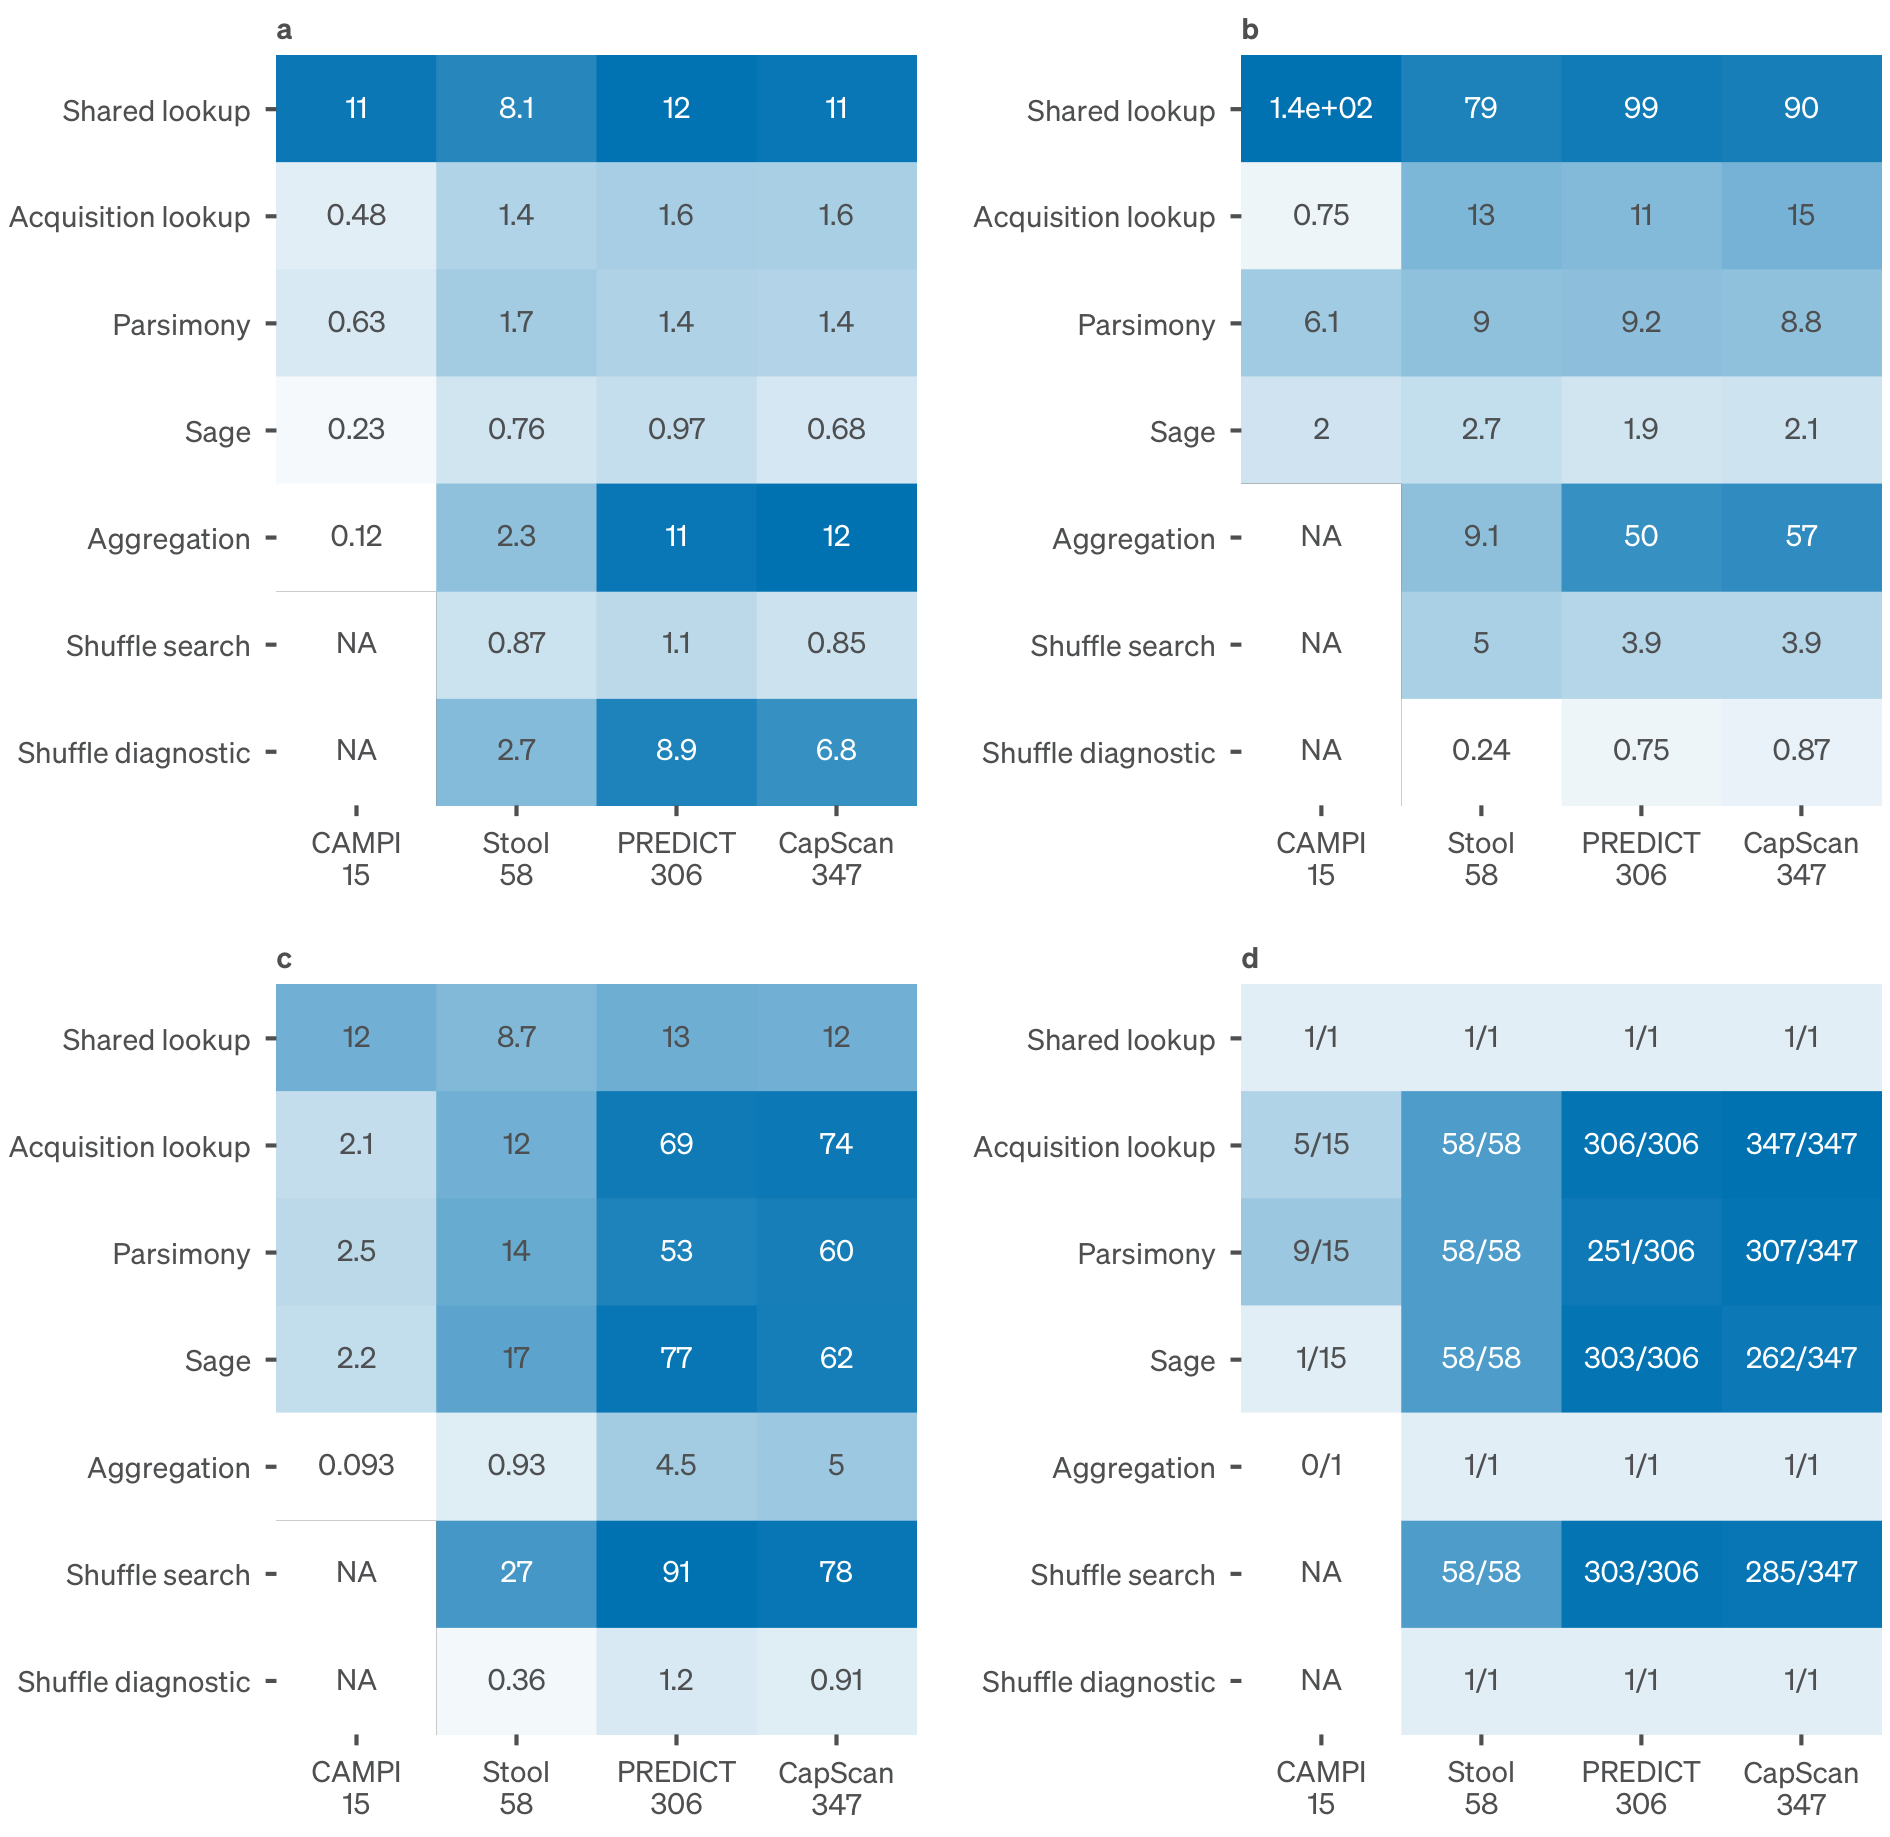

In [3]:
v30 = panels.figure_v30(s, OUT / "SFig15_v30", OUT / "producer_reference.pdf")
for line in v30["panels"]:
    print(line)
print("clip check:", v30["clip_ok"])
display(Image(filename=str(OUT / "SFig15_v30.png"), width=720))


## Panel a

Median task execution time in minutes per stage and cohort. Claim: "study-level lookup against reservoirs containing 233–375 million sequences required 8–12 min per cohort ... median database-selection times of 1–3 min per acquisition and Sage searches of less than 1 min" (v28d line 193); "Pooled extraction took 11 min. Median per-acquisition times for extraction, selection, and Sage/LFQ searching were 0.48, 0.63, and 0.23 min" (v28d line 299). n: Slurm tasks per cell (panel d prints them). Test: none (descriptive).
The values below are the labels printed in panel a, by the producer's label rule.

In [4]:
panels.panel_labels(s, "a")

,CAMPI,HSTOOL,PREDICT,CAPSCAN
Shared lookup,11,8.1,12,11
Acquisition lookup,0.48,1.4,1.6,1.6
Parsimony,0.63,1.7,1.4,1.4
Sage,0.23,0.76,0.97,0.68
Aggregation,0.12,2.3,11,12
Shuffle search,NA,0.87,1.1,0.85
Shuffle diagnostic,NA,2.7,8.9,6.8


## Panel b

Median usable sampled peak memory in GiB (2^30 bytes) per stage and cohort. Claim: legend only (v28d line 469). n: Slurm tasks per cell (panel d prints them). Test: none (descriptive).
The values below are the labels printed in panel b, by the producer's label rule.

In [5]:
panels.panel_labels(s, "b")

,CAMPI,HSTOOL,PREDICT,CAPSCAN
Shared lookup,1.4e+02,79,99,90
Acquisition lookup,0.75,13,11,15
Parsimony,6.1,9,9.2,8.8
Sage,2,2.7,1.9,2.1
Aggregation,NA,9.1,50,57
Shuffle search,NA,5,3.9,3.9
Shuffle diagnostic,NA,0.24,0.75,0.87


## Panel c

Sum of allocated CPU-hours per stage and cohort (allocated, not consumed). Claim: legend only (v28d line 469). n: Slurm tasks per cell (panel d prints them). Test: none (descriptive).
The values below are the labels printed in panel c, by the producer's label rule.

In [6]:
panels.panel_labels(s, "c")

,CAMPI,HSTOOL,PREDICT,CAPSCAN
Shared lookup,12,8.7,13,12
Acquisition lookup,2.1,12,69,74
Parsimony,2.5,14,53,60
Sage,2.2,17,77,62
Aggregation,0.093,0.93,4.5,5
Shuffle search,NA,27,91,78
Shuffle diagnostic,NA,0.36,1.2,0.91


## Panel d

Number of tasks with a usable memory sample / number of tasks. Claim: legend only (v28d line 469). n: Slurm tasks per cell (panel d prints them). Test: none (descriptive).
The values below are the labels printed in panel d, by the producer's label rule.

In [7]:
panels.panel_labels(s, "d")

,CAMPI,HSTOOL,PREDICT,CAPSCAN
Shared lookup,1/1,1/1,1/1,1/1
Acquisition lookup,5/15,58/58,306/306,347/347
Parsimony,9/15,58/58,251/306,307/347
Sage,1/15,58/58,303/306,262/347
Aggregation,0/1,1/1,1/1,1/1
Shuffle search,NA,58/58,303/306,285/347
Shuffle diagnostic,NA,1/1,1/1,1/1


## Checks and numbers

Pixel checks against the original producer's outputs: the figure before title removal and the
v28f composite PDF, both rasterised at 300 dpi, and the v28f 300 dpi PNG. Text is DejaVu Sans,
which ships with matplotlib, so these checks do not need the Söhne fonts and always run.
The v30 house-style composite is compared with the v30 image
(`expected/SFig15_v30.png`) only when `FASTALAKE_FONT_DIR` is set. Then every recomputed number, in `NUMBERS.tsv` order.

In [8]:
import pandas as pd
from tools.check_pixels import compare
for stem in ["panels_abcd", "SFig15_v28f"]:
    r = compare(OUT / f"{stem}.pdf", UNIT / "expected" / f"{stem}.pdf", UNIT / "checks" / stem, dpi=300)
    print(stem, "pdf@300dpi", r["verdict"], "differing pixels:", r.get("differing_pixels"))
r = compare(OUT / "SFig15_v28f.png", UNIT / "expected" / "SFig15_v28f.png", UNIT / "checks" / "SFig15_v28f_png")
print("SFig15_v28f.png", r["verdict"], "differing pixels:", r.get("differing_pixels"),
      "byte-identical:", r["new_sha256"] == r["expected_sha256"])
import os
if os.environ.get("FASTALAKE_FONT_DIR"):   # the v30 house style is set in Söhne
    r = compare(OUT / "SFig15_v30.png", UNIT / "expected" / "SFig15_v30.png", UNIT / "checks" / "SFig15_v30")
    print("SFig15_v30.png", r["verdict"], "differing pixels:", r.get("differing_pixels"),
          "byte-identical:", r["new_sha256"] == r["expected_sha256"])
else:
    print("v30 pixel check SKIPPED: fonts absent")

panels.check_sha256(SD / "campi_alphanovo_inference_sacct.tsv", panels.SACCT_SHA256)
SIZES = REPO / "source_data" / "Fig1" / "acquisition_sizes_726.tsv"   # owned by Fig1
panels.check_sha256(SIZES, panels.SIZES_SHA256)
res = panels.stat_reservoir_range(pd.read_csv(SIZES, sep="\t"))
lk = panels.stat_lookup_range(s)
sel = panels.stat_selection_per_acquisition(jobs)
med = panels.stat_stage_medians(s)
lake = panels.stat_campi_lake(jobs)
inf = panels.stat_campi_inference(panels.load_sacct(SD / "campi_alphanovo_inference_sacct.tsv"))
n = panels.stat_acquisition_counts(s)
print("selection per acquisition (median of summed 05+06 minutes):", sel["per_acquisition_median"], "n:", sel["n"])
print("alternative reading, sum of the two stage medians:", sel["sum_of_stage_medians"])
print("CAMPI inference:", inf)
print("CAMPI reservoir job:", lake)
numbers = [
    ("193", "reservoir_min_millions", res["min_millions"]),
    ("193", "reservoir_max_millions", res["max_millions"]),
    ("193", "lookup_min_minutes", lk["min"]),
    ("193", "lookup_max_minutes", lk["max"]),
    ("299", "campi_reservoir_minutes", lake["minutes"]),
    ("299", "campi_reservoir_program_threads", lake["program_threads"]),
    ("299", "node_memory_GB", "OPEN"),
    ("299", "campi_pooled_extraction_minutes", med["CAMPI"]["02_evidence"]),
    ("299", "campi_median_05_persample_minutes", med["CAMPI"]["05_persample"]),
    ("299", "campi_median_06_parsimony_minutes", med["CAMPI"]["06_parsimony"]),
    ("299", "campi_median_07_sage_minutes", med["CAMPI"]["07_sage"]),
    ("299", "campi_alphanovo_median_minutes", inf["median_minutes"]),
]
for line in ("469", "903"):
    numbers += [(line, "n_CAMPI", n["n"]["CAMPI"]), (line, "n_HSTOOL", n["n"]["HSTOOL"]),
                (line, "n_PREDICT", n["n"]["PREDICT"]), (line, "n_CAPSCAN", n["n"]["CAPSCAN"]),
                (line, "shared_scope_HSTOOL", n["shared_scope"]["HSTOOL"]),
                (line, "shared_scope_CAPSCAN", n["shared_scope"]["CAPSCAN"])]
for line, key, val in numbers:
    print(f"{line}\t{key}\t{val!r}")

panels_abcd pdf@300dpi IDENTICAL differing pixels: 0


SFig15_v28f pdf@300dpi IDENTICAL differing pixels: 0


SFig15_v28f.png IDENTICAL differing pixels: 0 byte-identical: True


SFig15_v30.png IDENTICAL differing pixels: 0 byte-identical: True
selection per acquisition (median of summed 05+06 minutes): {'CAMPI': 1.2333333333333334, 'HSTOOL': 3.2083333333333335, 'PREDICT': 3.1083333333333334, 'CAPSCAN': 2.966666666666667} n: {'CAMPI': 15, 'HSTOOL': 58, 'PREDICT': 306, 'CAPSCAN': 347}
alternative reading, sum of the two stage medians: {'CAMPI': 1.1166666666666667, 'HSTOOL': 3.1416666666666666, 'PREDICT': 3.091666666666667, 'CAPSCAN': 2.9333333333333336}
CAMPI inference: {'median_minutes': 28.266666666666666, 'n': 15, 'min_minutes': 13.233333333333333, 'max_minutes': 83.08333333333333}
CAMPI reservoir job: {'minutes': 92.36666666666666, 'program_threads': 64, 'allocated_logical_cpus': 128, 'jobid': '5895248'}
193	reservoir_min_millions	233.497702
193	reservoir_max_millions	375.333654
193	lookup_min_minutes	8.116666666666667
193	lookup_max_minutes	12.033333333333333
299	campi_reservoir_minutes	92.36666666666666
299	campi_reservoir_program_threads	64
299	node_memor